# Customers Like You: ML completion notebook (DE6, ML1 to ML7)

**Authors.** Original data engineering (`notebooks/data_exploration.ipynb`: DE1 to DE5 and the exploratory ML1/ML2
prototype): Alex Rees, Data Engineer (partner). ML completion (this notebook, the scripts, tests and docs):
Jiaxiao Chen, ML Engineer, 2026-10-12, prepared with AI assistance (Claude for implementation and drafting, Codex for planning and verification).

This notebook finishes the project started in `notebooks/data_exploration.ipynb` (the partner's DE1 to DE5 and
the exploratory ML1/ML2 prototype, kept unchanged as history). Here:

* **DE6**: `python build_matrix.py` rebuilds the partner's matrix from the raw Excel file in one command.
* **ML1 to ML7**: `python model_analysis.py` fits the models, each in its own fresh process for fair time and memory,
  then evaluates, compares and segments. The cells below rerun the analysis (cached fits are reused when the matrix
  and fitting code are unchanged; `python model_analysis.py --force` refits everything). They load the verified
  reports, and the key methods are demonstrated live.

Every number in the text comes from `reports/results.json` or is computed in a cell. None is typed in by hand.
Customer IDs never appear: customers are anonymous rows or segment names (R4).

In [1]:
import json, os, subprocess, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/ds5020-mpl")

in_venv = Path(sys.prefix).resolve() == (ROOT / ".venv").resolve()
print(f"Python {sys.version.split()[0]}, running from the project .venv: {in_venv}")

if not (ROOT / "data" / "processed" / "customer_product_quantity.npz").exists():
    subprocess.run([sys.executable, "build_matrix.py"], check=True)       # DE6: about 30 s
out = subprocess.run([sys.executable, "model_analysis.py"], check=True, capture_output=True, text=True)
print(out.stdout)

Python 3.12.14, running from the project .venv: True


ML2/ML5/ML7 fits (one fresh process per fit)
  reusing svd_log_k10
  reusing svd_log_k20
  reusing svd_log_k50
  reusing svd_log_k100
  reusing svd_log_k200
  reusing pca_log_k100
  reusing pca_log_k200
  reusing svd_count_k100
  reusing svd_binary_k100
Loading training data and held-out purchases
ML4 evaluation on held-out purchases
ML6 customer segments
ML7 purchase-value sensitivity
  SVD k=100: hit rate 0.232 (444/1913), PCA 0.229, best sellers 0.174
  nightly job 0.71 s, factors 7.328 MB
  wrote reports/results.json and 4 figures



In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Image, Markdown, display

import build_matrix as bm
import model_analysis as ma

pd.set_option("display.max_colwidth", 120)
REPORTS, FIGURES = ROOT / "reports", ROOT / "figures"
R = json.loads((REPORTS / "results.json").read_text())
M = json.loads((REPORTS / "matrix_report.json").read_text())
pct = lambda x: f"{100 * x:.1f}%"

## DE6: one command rebuilds the matrix

`python build_matrix.py` reads `data/raw/online_retail_II.xlsx`. If the file is missing, it extracts only that
file from `online+retail+ii.zip`. It then runs the partner's DE1 to DE5 steps unchanged:

1. **DE1**: load both sheets, map column-name variants (`InvoiceNo`, `UnitPrice`, `CustomerID`) to one canonical
   set, and profile every column.
2. **DE2**: remove rows in this fixed order: cancellations (`C` invoices), quantity <= 0, price <= 0, explicit
   non-product codes (postage, fees, samples, adjustments, tests) plus the `gift_0001_` voucher prefix, then missing
   customer IDs. Variant codes such as `85123A` remain separate products.
3. **DE3**: cutoff = last timestamp minus 2 calendar months. Training is everything before it. The test set keeps
   only test-period purchases of a product the customer had **never** bought before (repeat purchases are excluded).
4. **DE4**: sum the quantity per customer and product, then store `log(1 + total)`. Keep products bought by at least
   10 **training** customers, then drop customers left with no products. Rows and columns are sorted, so the
   mappings are stable. Product names are the most frequent training description (ties go to the alphabetically
   first name, and a product with no description falls back to its stock code).
5. **DE5**: report shape, non-zeros, sparsity, and dense vs CSR memory (values + column indices + row pointers).

Private files (anything with customer IDs) go to the git-ignored `data/processed/`. Aggregate reports go to `reports/`.

In [3]:
display(pd.read_csv(REPORTS / "sheet_counts.csv"))
display(pd.read_csv(REPORTS / "data_profile.csv"))
display(pd.read_csv(REPORTS / "cleaning_log.csv"))
display(pd.read_csv(REPORTS / "split_log.csv"))

,sheet,rows
0,Year 2009-2010,525461
1,Year 2010-2011,541910
2,Total,1067371


,column,dtype,non_null,missing,missing_pct,n_unique
0,Invoice,object,1067371,0,0.00,53628
1,StockCode,object,1067371,0,0.00,5305
2,Description,object,1062989,4382,0.41,5698
3,Quantity,int64,1067371,0,0.00,1057
4,InvoiceDate,datetime64[us],1067371,0,0.00,47635
5,Price,float64,1067371,0,0.00,2807
6,Customer ID,float64,824364,243007,22.77,5942
7,Country,str,1067371,0,0.00,43


,rule,reason,rows_removed,rows_remaining
0,Cancellations,Invoice starts with C,19494,1047877
1,Non-positive quantity,Quantity <= 0,3457,1044420
2,Non-positive price,Price <= 0,2750,1041670
3,Non-product codes,"Postage, fees, discounts, samples, adjustments, tests, vouchers",4666,1037004
4,Missing customer ID,Customer ID is null,234370,802634
5,Total removed,NaN,264737,802634


,split,rows,customers,products,start,end
0,Train (before cutoff),684071,5474,4530,2009-12-01 07:45:00,2011-10-09 12:49:00
1,Test (new products),72919,2308,2849,2011-10-09 13:11:00,2011-12-09 12:50:00
2,Test-period repeats excluded,45644,1872,2253,2011-10-09 12:59:00,2011-12-09 12:50:00


In [4]:
matrix_rows = ["customers", "products", "nonzeros", "sparsity_pct", "dense_mb", "sparse_mb", "sparse_data_bytes",
               "sparse_indices_bytes", "sparse_indptr_bytes", "cutoff", "products_dropped_by_min_buyers",
               "customers_dropped_with_no_kept_products", "test_customers_without_training_history",
               "test_rows_product_not_in_matrix"]
display(pd.Series({k: M[k] for k in matrix_rows}, name="value").to_frame())

# Regression check against the outputs printed in the partner's data_exploration.ipynb.
partner_notebook = {"raw_rows": 1_067_371, "clean_rows": 802_634, "train_rows": 684_071, "test_rows": 72_919,
                    "excluded_repeat_rows": 45_644, "customers": 5_473, "products": 3_687, "nonzeros": 413_927,
                    "cutoff": "2011-10-09 12:50:00"}
check = pd.DataFrame({"partner notebook": partner_notebook, "build_matrix.py": {k: M[k] for k in partner_notebook}})
check["same"] = check["partner notebook"] == check["build_matrix.py"]
display(check)
assert check["same"].all()

,value
customers,5473
products,3687
nonzeros,413927
sparsity_pct,97.948719
dense_mb,161.431608
sparse_mb,4.98902
sparse_data_bytes,3311416
sparse_indices_bytes,1655708
sparse_indptr_bytes,21896
cutoff,2011-10-09 12:50:00


,partner notebook,build_matrix.py,same
raw_rows,1067371,1067371,True
clean_rows,802634,802634,True
train_rows,684071,684071,True
test_rows,72919,72919,True
excluded_repeat_rows,45644,45644,True
customers,5473,5473,True
products,3687,3687,True
nonzeros,413927,413927,True
cutoff,2011-10-09 12:50:00,2011-10-09 12:50:00,True


## ML1: method decision (made before fitting)

The partner's ML1 note, recorded before any fit, chose **SVD**, and this notebook keeps that choice. The reasons
follow from the data, not from any result:

* The training matrix is about 98% zeros. **Truncated SVD works on the sparse matrix as it is.** A zero keeps its
  meaning ("did not buy"), and one fit gives customer factors (U S) and product factors (V), which is what an
  item-to-item recommender needs.
* **PCA centres each column first.** The zeros become small negative numbers, so the components describe deviations
  from the average customer, and a centred matrix is dense. scikit-learn >= 1.4 can centre implicitly on sparse
  input with `svd_solver="arpack"`, so ML5 runs PCA on exactly the same matrix and k as the comparison.
* Operational model: `TruncatedSVD(n_components=100, algorithm="arpack", random_state=42)` on the sparse CSR
  matrix. The partner's dense `np.linalg.svd(A.toarray())` in ML2 remains as history only, because it needs the
  161 MB dense matrix. ARPACK was chosen over the default randomized solver because it returns the exact top-k
  factors (it reproduces the partner's dense-SVD errors to 4 decimals) at the same cost. The choice used training
  reconstruction error only, and PCA uses the same ARPACK solver, so the comparison is like-for-like.

## ML2: reconstruction error against k, and the choice of k

Each k in {10, 20, 50, 100, 200} is a **separate** sparse TruncatedSVD fit, in a fresh process. The error never
builds a dense matrix: V has orthonormal columns, so

$$\|A - AVV^\top\|_F^2 = \|A\|_F^2 - \|AV\|_F^2 .$$

,k,relative_error,fit_seconds,peak_rss_mb,factor_mb,error_drop_per_component,svd_share_of_squared_norm_kept,pca_variance_explained,within_factor_target
0,10,0.8761,0.0316,178.6020,0.7328,0.0030,0.2325,0.1986,True
1,20,0.8458,0.0452,181.8132,1.4656,0.0019,0.2846,0.2527,True
2,50,0.7892,0.0973,192.6431,3.6640,0.0012,0.3771,0.3493,True
3,100,0.7268,0.1860,210.7638,7.3280,0.0009,0.4718,0.4481,True
4,200,0.6379,0.4470,244.4984,14.6560,NaN,0.5931,0.5748,False


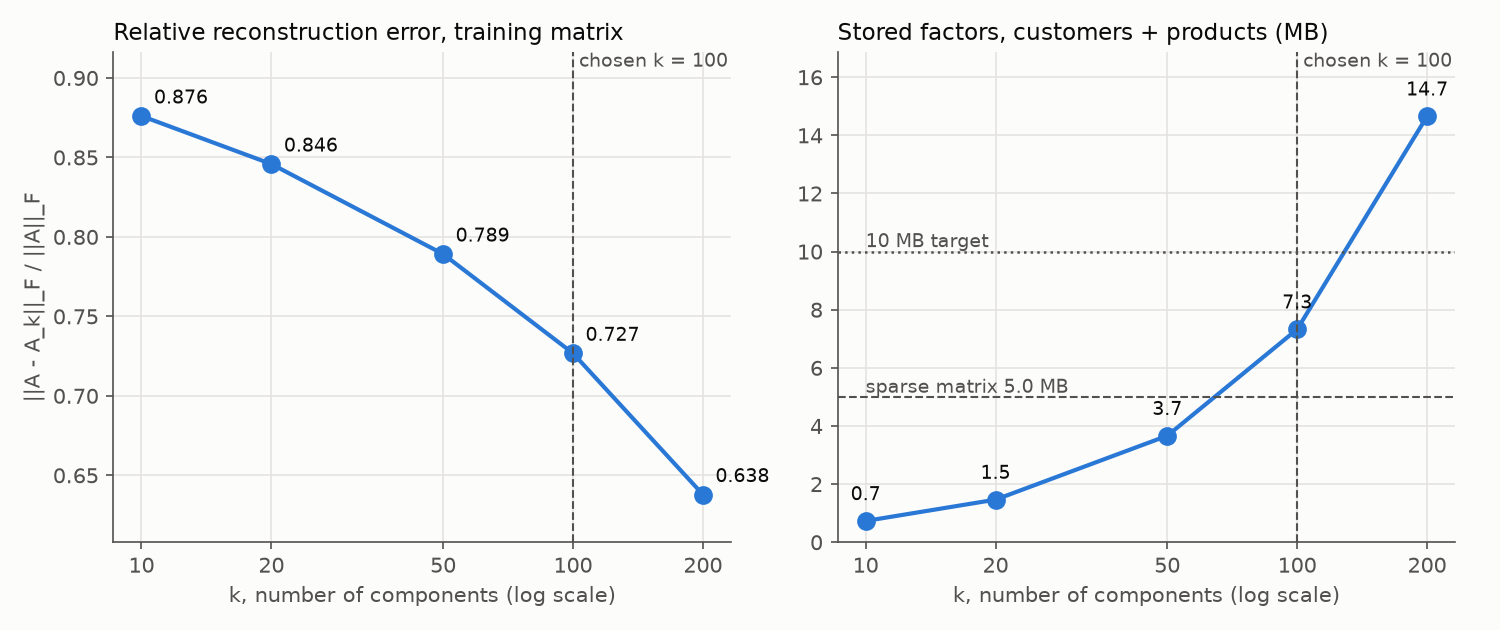

In [5]:
curve = pd.read_csv(REPORTS / "svd_curve.csv")
display(curve.round(4))
display(Image(FIGURES / "svd_curve.png"))

In [6]:
# Live check of the method: refit k = 10 here and recompute the error with the sparse formula.
A = ma.load_matrix("log")
Q = ma.load_quantity_matrix()
svd10 = ma.fit_decomposition(A, "svd", 10)
live = ma.relative_error_svd(A, svd10.components_)
print(f"k=10 relative error, refit now: {live:.6f}   from the fresh-process sweep: {curve.loc[0, 'relative_error']:.6f}")

# The partner's historical dense SVD (data_exploration.ipynb, ML2) printed these errors:
partner_dense = {10: 0.8761, 20: 0.8458, 50: 0.7892, 100: 0.7268, 200: 0.6379}
print(pd.DataFrame({"partner dense SVD": partner_dense,
                    "sparse ARPACK fits": dict(zip(curve["k"], curve["relative_error"].round(4)))}))

k=10 relative error, refit now: 0.876083   from the fresh-process sweep: 0.876083
     partner dense SVD  sparse ARPACK fits
10              0.8761              0.8761
20              0.8458              0.8458
50              0.7892              0.7892
100             0.7268              0.7268
200             0.6379              0.6379


In [7]:
c = curve.set_index("k")
k = R["chosen_k"]
display(Markdown(f'''
**Chosen k = {k}, declared by the partner before evaluation and kept.** The evidence is training-only:

* Error falls from {c.loc[10, "relative_error"]:.3f} (k=10) to {c.loc[50, "relative_error"]:.3f} (k=50),
  {c.loc[100, "relative_error"]:.3f} (k=100) and {c.loc[200, "relative_error"]:.3f} (k=200). Each step buys less per
  added component (the error falls {c.loc[10, "error_drop_per_component"]:.4f} per component from 10 to 20, but
  only {c.loc[100, "error_drop_per_component"]:.4f} from 100 to 200), yet the curve has no sharp elbow.
* Storage decides it. Factors take {c.loc[50, "factor_mb"]:.2f} MB at k=50, **{c.loc[100, "factor_mb"]:.2f} MB at
  k=100** and {c.loc[200, "factor_mb"]:.2f} MB at k=200, against a {R["targets"]["factor_mb_max"]:.0f} MB target.
  So k=100 is the largest swept k that keeps the most detail within budget.
* An error of {c.loc[100, "relative_error"]:.2f} sounds large, but it is normal for sparse purchase data: k=100
  keeps {100 * c.loc[100, "svd_share_of_squared_norm_kept"]:.0f}% of the squared norm. The remainder is mostly
  one-off purchases that no low-rank pattern can predict.

Test hit rates for every k are in `reports/k_test_descriptive.csv`. They were computed **after** k was fixed, and
are descriptive only.
'''))


**Chosen k = 100, declared by the partner before evaluation and kept.** The evidence is training-only:

* Error falls from 0.876 (k=10) to 0.789 (k=50),
  0.727 (k=100) and 0.638 (k=200). Each step buys less per
  added component (the error falls 0.0030 per component from 10 to 20, but
  only 0.0009 from 100 to 200), yet the curve has no sharp elbow.
* Storage decides it. Factors take 3.66 MB at k=50, **7.33 MB at
  k=100** and 14.66 MB at k=200, against a 10 MB target.
  So k=100 is the largest swept k that keeps the most detail within budget.
* An error of 0.73 sounds large, but it is normal for sparse purchase data: k=100
  keeps 47% of the squared norm. The remainder is mostly
  one-off purchases that no low-rank pattern can predict.

Test hit rates for every k are in `reports/k_test_descriptive.csv`. They were computed **after** k was fixed, and
are descriptive only.


## ML3: recommendations

* **Product vectors**: `P = normalize(components_.T)`, one unit-length row per product, so a dot product is
  cosine similarity.
* **"Customers who bought this also bought"**: the 10 most cosine-similar products, excluding the product itself.
  All 3,687 products are scored in batches, and only the top-10 index/score table is kept (no product x product
  matrix is stored).
* **For a customer**: profile = (customer's row of A) @ P, and candidate score = profile @ P^T. This equals
  sum over bought products j of a_ij x cos(j, candidate): products similar to what they bought, each past product
  weighted by its purchase value. Every product already bought is excluded.
* Ties go to the lower column index (stable sort). Every list is exactly 10 wide: 10 distinct products whenever at
  least 10 candidates remain, otherwise the tail is padded with index -1 (score -inf). The cells below drop
  negative indices before looking up product names.

In [8]:
products = pd.read_csv(ROOT / "data" / "processed" / "product_index.csv", dtype={"stock_code": str})
names = products["description"].to_numpy()
factors, recs = ma.load_fit("svd_log_k100")
P = ma.product_vectors(factors["product_factors"])

j = int(products.index[products["stock_code"] == "85123A"][0])
idx, score = ma.recommend_similar(j, P)
assert (idx == recs["item_top_idx"][j]).all()        # same as the nightly batch table
keep = idx >= 0                                      # drop -1 padding (none here: the catalogue has 3,687 products)
print(f"Customers who bought {names[j]} also bought:")
display(pd.DataFrame({"product": names[idx[keep]], "cosine": score[keep].round(3)}, index=range(1, keep.sum() + 1)))

Customers who bought WHITE HANGING HEART T-LIGHT HOLDER also bought:


,product,cosine
1,RED HANGING HEART T-LIGHT HOLDER,0.751
2,CANDLEHOLDER PINK HANGING HEART,0.615
3,RED HANGING METAL STAR TLIGHT HLDR,0.316
4,JAZZ HEARTS SPIRAL NOTEPAD,0.282
5,CREAM HEART CARD HOLDER,0.280
6,COLOUR GLASS. STAR T-LIGHT HOLDER,0.266
7,SCALLOP SHELL SOAP DISH,0.233
8,TREE T-LIGHT HOLDER WILLIE WINKIE,0.206
9,WHITE HYDRANGEA ART FLOWER,0.200
10,GLASS STAR FROSTED T-LIGHT HOLDER,0.193


In [9]:
# One anonymous warm test customer ("customer A"): the first matrix row in the evaluation cohort with
# at least 20 past products. The ID itself is never loaded into the output.
customer_ids = pd.read_csv(ROOT / "data" / "processed" / "customer_index.csv")["customer_id"].to_numpy()
test = pd.read_csv(ROOT / "data" / "processed" / "test.csv", dtype={"StockCode": str})
targets, coverage = ma.heldout_targets(test, customer_ids, products["stock_code"].to_numpy())
row = next(r for r in sorted(targets) if A[r].nnz >= 20)
history = A[row].toarray().ravel()
top_past = np.argsort(-history, kind="stable")[:5]
print("Customer A's five largest past purchases:", "; ".join(names[top_past]))

model_idx, _ = ma.recommend_for_customer(row, A, P)
baseline_idx = ma.best_seller_recommendations(A[row], ma.best_seller_totals(Q))[0]
model_idx, baseline_idx = model_idx[model_idx >= 0], baseline_idx[baseline_idx >= 0]    # drop any -1 padding
assert len(model_idx) == len(baseline_idx) == 10
held_out = set(targets[row])
display(pd.DataFrame({
    "SVD recommendation": names[model_idx], "bought in test?": ["yes" if i in held_out else "" for i in model_idx],
    "best-seller baseline": names[baseline_idx], "bought in test? ": ["yes" if i in held_out else "" for i in baseline_idx],
}, index=range(1, 11)))

Customer A's five largest past purchases: ICE CREAM SUNDAE LIP GLOSS; 3D DOG PICTURE PLAYING CARDS; MINI PAINT SET VINTAGE; 60 TEATIME FAIRY CAKE CASES; 72 SWEETHEART FAIRY CAKE CASES


,SVD recommendation,bought in test?,best-seller baseline,bought in test?
1,BLACK ORANGE SQUEEZER,,WORLD WAR 2 GLIDERS ASSTD DESIGNS,
2,"PINK/WHITE ""KEEP CLEAN"" BULLET BIN",,PACK OF 72 RETROSPOT CAKE CASES,
3,SILVER TEDDY BEAR,,WHITE HANGING HEART T-LIGHT HOLDER,
4,HEART EAR MUFF HEADPHONES,,JUMBO BAG RED RETROSPOT,
5,GOLD EAR MUFF HEADPHONES,,MEDIUM CERAMIC TOP STORAGE JAR,
6,ANTIQUE SILVER BAUBLE LAMP,,ASSORTED COLOUR BIRD ORNAMENT,
7,SET OF 3 BIRD L.BLUE FEATHER,,BROCADE RING PURSE,
8,VIPPASSPORT COVER,,SMALL POPCORN HOLDER,
9,PINK STOCKING CHRISTMAS DECORATION,,PACK OF 60 PINK PAISLEY CAKE CASES,
10,S/3 PINK SQUARE PLANTERS ROSES,,ASSORTED COLOURS SILK FAN,


## ML4: evaluation on held-out purchases, and the nightly job

* **Primary cohort**: every warm test customer (a row in the training matrix) with at least one held-out new
  product that is in the training catalogue. The SVD, PCA, every sensitivity variant and the baseline are all
  scored on this one fixed cohort, with the same catalogue and the same purchase history excluded.
* **Hit rate at 10**: the share of the cohort for whom at least one held-out product is in their top 10. A customer
  with several held-out products counts once. **Recall at 10** is also shown: for each customer, the share of their
  held-out catalogue products that appear in the top 10, averaged over customers. The denominator is not capped at
  10, so 1 hit out of 20 held-out products counts as 0.05.
* **Baseline (R3)**: catalogue products ranked by total **training** quantity. Each customer's already-bought
  products are removed and the list is refilled from lower ranks to 10.
* Coverage is reported, not hidden, and three different rates are kept apart: **customer** coverage (cohort
  customers / all test customers), **pair** coverage (held-out (customer, product) pairs with a warm customer and a
  catalogue product / all test pairs) and **product** coverage (distinct test products in the catalogue / all
  distinct test products). Cold-start customers and products outside the catalogue cannot be scored by any model,
  so the broader warm and all-test rates count them as misses.

value
counts                    measure                                     
customers                 total_test_customers                  2308.0
                          warm_test_customers                   1930.0
                          cold_start_customers                   378.0
                          warm_customers_no_eligible_product      17.0
                          eligible_customers                    1913.0
                          eligible_customer_coverage_pct          82.9
(customer, product) pairs total_test_pairs                     63252.0
                          eligible_test_pairs                  44727.0
                          cold_customer_pairs                  13829.0
                          warm_pairs_product_not_in_catalogue   4696.0
                          eligible_pair_coverage_pct              70.7
distinct products         test_products                         2849.0
                          test_products_in_catalogue            2555.0
                          eligible_product_coverage_pct           89.7

eligible_customer_coverage_pct: eligible customers / all distinct test customers
eligible_pair_coverage_pct: held-out (customer, product) pairs with a warm customer and a catalogue product / all distinct test pairs
eligible_product_coverage_pct: distinct test products in the training catalogue / all distinct test products


,hit rate at 10,hits,customers,95% bootstrap low,95% bootstrap high,recall at 10,warm-customer rate,all-test-customer rate
Truncated SVD k=100,0.2321,444.0,1913.0,0.2128,0.2515,0.0284,0.2301,0.1924
PCA k=100,0.2290,438.0,1913.0,0.2101,0.2483,0.0282,0.2269,0.1898
Best sellers,0.1741,333.0,1913.0,0.1563,0.1924,0.0115,0.1725,0.1443


Bootstrap columns: 95% customer bootstrap interval for each method's own hit rate.
Paired comparisons (difference = first minus second; paired-bootstrap 95% interval; exact McNemar test):


,difference,ci95_low,ci95_high,only_first_hit,only_second_hit,mcnemar_exact_p
svd_vs_baseline,0.0580,0.0340,0.0826,331.0,220.0,0.0000
pca_vs_baseline,0.0549,0.0308,0.0800,325.0,220.0,0.0000
svd_vs_pca,0.0031,-0.0005,0.0073,11.0,5.0,0.2101


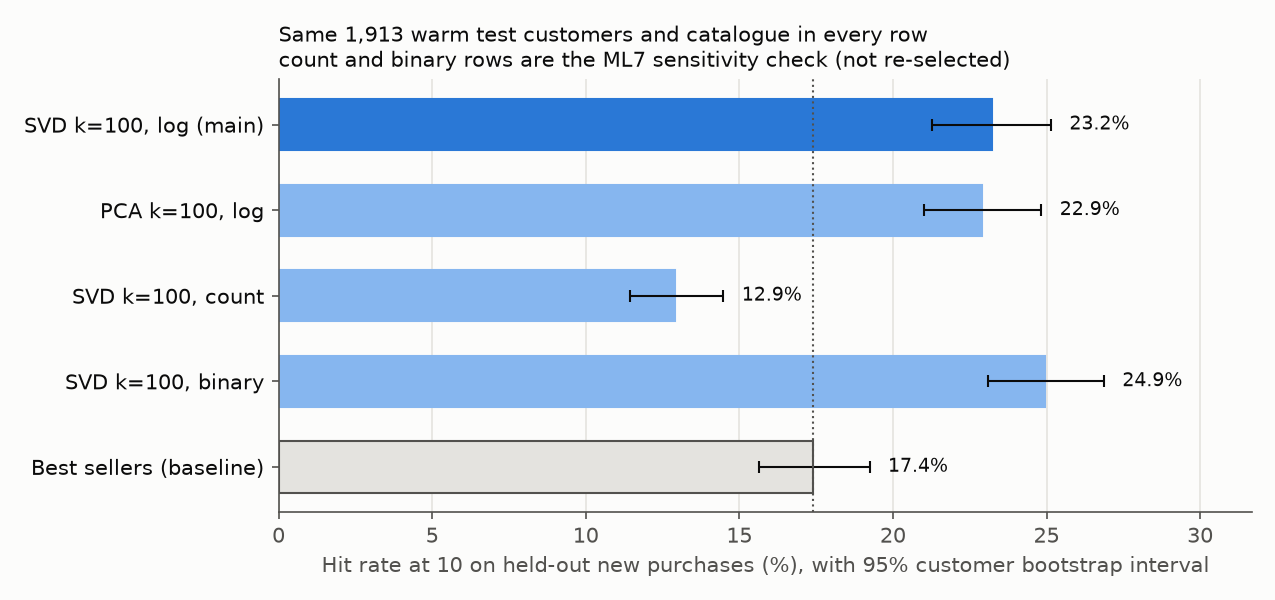

Descriptive only (k was fixed before these were computed):


,k,hit_rate_at_10,hits,evaluated_customers,note
0,10,0.1448,277,1913,descriptive only; not used to choose k
1,20,0.1830,350,1913,descriptive only; not used to choose k
2,50,0.2128,407,1913,descriptive only; not used to choose k
3,100,0.2321,444,1913,descriptive only; not used to choose k
4,200,0.2190,419,1913,descriptive only; not used to choose k


In [10]:
E = R["evaluation"]
cov_rows = {
    "customers": ["total_test_customers", "warm_test_customers", "cold_start_customers",
                  "warm_customers_no_eligible_product", "eligible_customers", "eligible_customer_coverage_pct"],
    "(customer, product) pairs": ["total_test_pairs", "eligible_test_pairs", "cold_customer_pairs",
                                  "warm_pairs_product_not_in_catalogue", "eligible_pair_coverage_pct"],
    "distinct products": ["test_products", "test_products_in_catalogue", "eligible_product_coverage_pct"],
}
display(pd.DataFrame([(unit, k, round(E[k], 1)) for unit, keys in cov_rows.items() for k in keys],
                     columns=["counts", "measure", "value"]).set_index(["counts", "measure"]))
print("\n".join(f"{k}: {v}" for k, v in E["coverage_definitions"].items()))

table = pd.DataFrame({name: {
    "hit rate at 10": R[key]["hit_rate_at_10"], "hits": R[key]["hits"], "customers": R[key]["evaluated_customers"],
    "95% bootstrap low": R[key]["hit_rate_ci95_low"], "95% bootstrap high": R[key]["hit_rate_ci95_high"],
    "recall at 10": R[key]["recall_at_10"], "warm-customer rate": R[key]["warm_hit_rate_at_10"],
    "all-test-customer rate": R[key]["all_test_hit_rate_at_10"]}
    for name, key in [("Truncated SVD k=100", "svd"), ("PCA k=100", "pca"), ("Best sellers", "baseline")]}).T
display(table.round(4))
print("Bootstrap columns: 95% customer bootstrap interval for each method's own hit rate.")
print("Paired comparisons (difference = first minus second; paired-bootstrap 95% interval; exact McNemar test):")
display(pd.DataFrame(E["comparisons"]).T.round(4))
display(Image(FIGURES / "evaluation.png"))
print("Descriptive only (k was fixed before these were computed):")
display(pd.read_csv(REPORTS / "k_test_descriptive.csv").round(4))

In [11]:
s, b, cmp = R["svd"], R["baseline"], E["comparisons"]["svd_vs_baseline"]
display(Markdown(f'''
**Result: the SVD recommender beats best sellers on purchases it never saw.** Of the {s["evaluated_customers"]:,}
cohort customers, {s["hits"]} ({pct(s["hit_rate_at_10"])}) had a held-out product in their SVD top 10, against
{b["hits"]} ({pct(b["hit_rate_at_10"])}) for best sellers. That is {100 * cmp["difference"]:.1f} percentage points
more, or {s["hit_rate_at_10"] / b["hit_rate_at_10"]:.2f} times the baseline. The paired-bootstrap 95% interval for
the gain is {100 * cmp["ci95_low"]:.1f} to {100 * cmp["ci95_high"]:.1f} points. {cmp["only_first_hit"]} customers
were hit only by the SVD and {cmp["only_second_hit"]} only by best sellers (exact McNemar p = {cmp["mcnemar_exact_p"]:.1g}).

How far to trust it:

* The gain is clear, but its size is uncertain by about +/-{50 * (cmp["ci95_high"] - cmp["ci95_low"]):.1f} points
  with {s["evaluated_customers"]:,} customers. The test is one window ({R["data"]["test_start"][:10]} to
  {R["data"]["test_end"][:10]}, the pre-Christmas peak), so a different season could change the gap.
* Recall is low for every method ({pct(s["recall_at_10"])} for SVD, {pct(b["recall_at_10"])} for best sellers).
  A cohort customer bought {E["eligible_test_pairs"] / E["eligible_customers"]:.1f} new catalogue products on average
  in the test window, and 10 slots catch only a few.
* Coverage, three ways: the cohort is {E["eligible_customer_coverage_pct"]:.1f}% of test customers
  ({E["eligible_customers"]:,} / {E["total_test_customers"]:,}); it holds {E["eligible_pair_coverage_pct"]:.1f}% of
  held-out (customer, product) pairs ({E["eligible_test_pairs"]:,} / {E["total_test_pairs"]:,}); and
  {E["eligible_product_coverage_pct"]:.1f}% of distinct test products are in the training catalogue
  ({E["test_products_in_catalogue"]:,} / {E["test_products"]:,}). {E["cold_start_customers"]} test customers have no
  training history. Counting every test customer, the SVD rate is
  {pct(s["all_test_hit_rate_at_10"])}. If cold customers are shown best sellers (a realistic deployment), it is
  {pct(E["svd_all_test_hit_rate_with_cold_fallback"])}, against {pct(E["baseline_all_test_hit_rate_with_cold_fallback"])}
  for best sellers alone.
'''))


**Result: the SVD recommender beats best sellers on purchases it never saw.** Of the 1,913
cohort customers, 444 (23.2%) had a held-out product in their SVD top 10, against
333 (17.4%) for best sellers. That is 5.8 percentage points
more, or 1.33 times the baseline. The paired-bootstrap 95% interval for
the gain is 3.4 to 8.3 points. 331 customers
were hit only by the SVD and 220 only by best sellers (exact McNemar p = 3e-06).

How far to trust it:

* The gain is clear, but its size is uncertain by about +/-2.4 points
  with 1,913 customers. The test is one window (2011-10-09 to
  2011-12-09, the pre-Christmas peak), so a different season could change the gap.
* Recall is low for every method (2.8% for SVD, 1.2% for best sellers).
  A cohort customer bought 23.4 new catalogue products on average
  in the test window, and 10 slots catch only a few.
* Coverage, three ways: the cohort is 82.9% of test customers
  (1,913 / 2,308); it holds 70.7% of
  held-out (customer, product) pairs (44,727 / 63,252); and
  89.7% of distinct test products are in the training catalogue
  (2,555 / 2,849). 378 test customers have no
  training history. Counting every test customer, the SVD rate is
  19.2%. If cold customers are shown best sellers (a realistic deployment), it is
  25.0%, against 20.2%
  for best sellers alone.


In [12]:
N = R["nightly"]
display(pd.Series({
    "fit TruncatedSVD k=100 (s)": N["fit_seconds"], "normalise product vectors (s)": N["normalization_seconds"],
    "top-10 neighbours for all products (s)": N["item_scoring_seconds"], "nightly job total (s)": N["total_seconds"],
    "personalised top-10 for all customers (s, separate)": N["customer_scoring_seconds"],
}, name="seconds").round(4).to_frame())
env = R["environment"]
display(Markdown(f'''
The nightly computation stage for the product pages (fit + normalise + top-10 for all {N["products_scored"]:,}
products) takes **{N["total_seconds"]:.2f} s** against a {N["target_seconds"]:.0f} s target. Scoring personalised top-10
lists for all {N["customers_scored"]:,} customers adds {N["customer_scoring_seconds"]:.2f} s. This is a kernel benchmark:
the median of 5 runs on the prepared in-memory matrix, in a fresh process on {env["cpu"]} ({env["logical_cpus"]}
logical CPUs, {env["ram_gb"]:.0f} GB RAM, {env["platform"]}), with BLAS/OpenMP pinned to one thread. It excludes
{N["excludes"]}, so it is not an end-to-end production runtime (the whole `model_analysis.py` run, with its many
fits and evaluation, takes about 90 s). These times are specific to this machine.
'''))

,seconds
fit TruncatedSVD k=100 (s),0.1860
normalise product vectors (s),0.0003
top-10 neighbours for all products (s),0.5207
nightly job total (s),0.7070
"personalised top-10 for all customers (s, separate)",0.7868



The nightly computation stage for the product pages (fit + normalise + top-10 for all 3,687
products) takes **0.71 s** against a 60 s target. Scoring personalised top-10
lists for all 5,473 customers adds 0.79 s. This is a kernel benchmark:
the median of 5 runs on the prepared in-memory matrix, in a fresh process on Apple M4 (10
logical CPUs, 17 GB RAM, macOS-26.2-arm64-arm-64bit), with BLAS/OpenMP pinned to one thread. It excludes
raw Excel reading and cleaning, Python imports, loading and saving files, deployment and network, so it is not an end-to-end production runtime (the whole `model_analysis.py` run, with its many
fits and evaluation, takes about 90 s). These times are specific to this machine.


## ML5: PCA against Truncated SVD on the same matrix and k

PCA runs as `PCA(n_components=100, svd_solver="arpack", random_state=42)` on the **same sparse log matrix**.
Centring is implicit, there is no scaling, and the matrix is never densified. Both methods use the same cosine
recommender and the same evaluation cohort. Fit time and peak memory come from a fresh process per method:
resident memory (RSS) is sampled every 1 ms during the first fit, and the `ru_maxrss` high-water mark is kept as a
cross-check.

In [13]:
display(pd.read_csv(REPORTS / "comparison.csv"))

,measure,PCA,Truncated SVD
0,k used,100,100
1,Fit time (seconds),0.19,0.186
2,"Peak memory during fit (MB, process RSS)",202.0,210.8
3,"Memory increase during fit (MB, above loaded matrix)",29.3,37.9
4,"Size of stored factors (MB, customers + products [+ mean])",7.357,7.328
5,Variance explained (PCA) / relative reconstruction error (SVD),44.8% variance explained,0.7268 relative error
6,Relative reconstruction error of A (same formula for both),0.7266,0.7268
7,Hit rate at 10 on held-out purchases,22.9% (438/1913),23.2% (444/1913)
8,Best-seller baseline hit rate at 10,17.4% (333/1913),17.4% (333/1913)
9,"What component 1 represents, in words",Overall buying volume: scores rise with how much and how widely a customer buys (r = 0.68 with log total quantity; 1...,Overall buying volume: scores rise with how much and how widely a customer buys (r = 0.69 with log total quantity; 1...


In [14]:
s, p = R["svd"], R["pca"]
storage = pd.DataFrame({"MB": {
    "dense customer x product matrix (float64)": R["matrix"]["dense_mb"],
    "sparse CSR arrays in memory (values + indices + row pointers)": R["matrix"]["sparse_mb"],
    "SVD factors: customers (5,473 x 100) + products (3,687 x 100)": s["factor_mb"],
    "PCA factors: customers + products + mean vector": p["factor_mb"],
    "SVD factor file on disk (.npz, uncompressed)": s["factor_file_mb"],
    "product vectors only (enough for product pages)": s["product_vectors_mb"],
    "precomputed top-10 table for all products (int32 + float32)": s["item_top10_table_mb"],
}})
display(storage.round(3))
display(pd.DataFrame({"SVD": s, "PCA": p}).loc[["rss_after_imports_mb", "rss_loaded_matrix_mb", "peak_rss_mb",
                                                 "rss_increase_mb", "ru_maxrss_after_fit_mb", "fit_seconds"]].round(3))

,MB
dense customer x product matrix (float64),161.432
sparse CSR arrays in memory (values + indices + row pointers),4.989
"SVD factors: customers (5,473 x 100) + products (3,687 x 100)",7.328
PCA factors: customers + products + mean vector,7.357
"SVD factor file on disk (.npz, uncompressed)",7.329
product vectors only (enough for product pages),2.950
precomputed top-10 table for all products (int32 + float32),0.295


,SVD,PCA
rss_after_imports_mb,166.346752,166.21568
rss_loaded_matrix_mb,172.867584,172.720128
peak_rss_mb,210.763776,201.981952
rss_increase_mb,37.896192,29.261824
ru_maxrss_after_fit_mb,210.796544,201.998336
fit_seconds,0.185992,0.189538


In [15]:
d = E["comparisons"]["svd_vs_pca"]
display(Markdown(f'''
**What the comparison shows, in our own numbers**

* **Recommendations: a small observed gap that this sample cannot confirm.** SVD hits {pct(s["hit_rate_at_10"])}
  ({s["hits"]}), PCA {pct(p["hit_rate_at_10"])} ({p["hits"]}), an observed difference of {100 * d["difference"]:.1f}
  points. Only {d["only_first_hit"] + d["only_second_hit"]} of {s["evaluated_customers"]:,} customers differ
  (paired 95% interval {100 * d["ci95_low"]:.1f} to {100 * d["ci95_high"]:.1f} points, McNemar p = {d["mcnemar_exact_p"]:.2f}),
  so no difference is shown in this sample. That is not proof the two are equivalent. Both beat best sellers.
* **Information kept**: PCA's 100 components explain {pct(p["variance_explained"])} of the *centred* variance, which
  is the same statement as a centred error of {p["relative_error_centred"]:.3f}. Rebuilding A itself (PCA adds the
  mean back), the errors are almost identical: PCA {p["relative_error"]:.4f}, SVD {s["relative_error"]:.4f}. PCA is
  very slightly lower because the stored mean vector acts as one extra component.
* **Component 1 is "buying volume" for both.** SVD: {s["component_1_description"]}. PCA: r = {p["component_1_volume_correlation"]:.2f}.
  Centring does not remove the volume direction, because heavy buyers are also the largest deviations from the average.
* **Cost**: fits take {s["fit_seconds"]:.2f} s (SVD) and {p["fit_seconds"]:.2f} s (PCA). Peak process memory is
  {s["peak_rss_mb"]:.0f} MB and {p["peak_rss_mb"]:.0f} MB. About {s["rss_after_imports_mb"]:.0f} MB of that is just
  Python + numpy/pandas/scikit-learn being loaded, so the fit itself adds {s["rss_increase_mb"]:.0f} MB and
  {p["rss_increase_mb"]:.0f} MB above the loaded matrix. That extra is far below the {R["matrix"]["dense_mb"]:.0f} MB
  a dense copy of A alone would add, because neither method densifies the matrix.
* **Why SVD stays the main model**: it is native to sparse data, a zero keeps meaning "not bought", there is no mean
  vector to store or explain, and PCA did not do better here. PCA's implicit centring only works with special solvers,
  and its components describe "different from the average customer", which is harder to explain to Sarah.

**Compression trade-off**: the dense matrix would take {R["matrix"]["dense_mb"]:.1f} MB. The SVD factors take
{s["factor_mb"]:.3f} MB, **{R["matrix"]["dense_mb"] / s["factor_mb"]:.0f} times smaller**, but honestly *larger*
than the {R["matrix"]["sparse_mb"]:.1f} MB of in-memory CSR arrays. The gain over the sparse matrix is not size. It is that every
product gets a dense 100-number vector, so similar products can be found in milliseconds without comparing every
customer with every product. The product pages need only the {s["product_vectors_mb"]:.2f} MB of product vectors,
or just the {s["item_top10_table_mb"]:.2f} MB top-10 table. What compression loses: an exact rebuild of A
(relative error {s["relative_error"]:.2f}); the dropped detail is mostly rare, one-off purchases.
'''))


**What the comparison shows, in our own numbers**

* **Recommendations: a small observed gap that this sample cannot confirm.** SVD hits 23.2%
  (444), PCA 22.9% (438), an observed difference of 0.3
  points. Only 16 of 1,913 customers differ
  (paired 95% interval -0.1 to 0.7 points, McNemar p = 0.21),
  so no difference is shown in this sample. That is not proof the two are equivalent. Both beat best sellers.
* **Information kept**: PCA's 100 components explain 44.8% of the *centred* variance, which
  is the same statement as a centred error of 0.743. Rebuilding A itself (PCA adds the
  mean back), the errors are almost identical: PCA 0.7266, SVD 0.7268. PCA is
  very slightly lower because the stored mean vector acts as one extra component.
* **Component 1 is "buying volume" for both.** SVD: Overall buying volume: scores rise with how much and how widely a customer buys (r = 0.69 with log total quantity; 100% of product loadings share one sign). PCA: r = 0.68.
  Centring does not remove the volume direction, because heavy buyers are also the largest deviations from the average.
* **Cost**: fits take 0.19 s (SVD) and 0.19 s (PCA). Peak process memory is
  211 MB and 202 MB. About 166 MB of that is just
  Python + numpy/pandas/scikit-learn being loaded, so the fit itself adds 38 MB and
  29 MB above the loaded matrix. That extra is far below the 161 MB
  a dense copy of A alone would add, because neither method densifies the matrix.
* **Why SVD stays the main model**: it is native to sparse data, a zero keeps meaning "not bought", there is no mean
  vector to store or explain, and PCA did not do better here. PCA's implicit centring only works with special solvers,
  and its components describe "different from the average customer", which is harder to explain to Sarah.

**Compression trade-off**: the dense matrix would take 161.4 MB. The SVD factors take
7.328 MB, **22 times smaller**, but honestly *larger*
than the 5.0 MB of in-memory CSR arrays. The gain over the sparse matrix is not size. It is that every
product gets a dense 100-number vector, so similar products can be found in milliseconds without comparing every
customer with every product. The product pages need only the 2.95 MB of product vectors,
or just the 0.29 MB top-10 table. What compression loses: an exact rebuild of A
(relative error 0.73); the dropped detail is mostly rare, one-off purchases.


## ML6: customer map and segments

* Inputs: the first two customer components of the chosen **training-only** SVD fit (signs oriented so product
  loadings sum to a positive number).
* Component 1 is overall volume, and it is very skewed: k-means on the raw pair puts about 12 huge accounts in a
  segment of their own. The same two numbers are therefore written in polar form. **Size** = log10 of the distance
  from the origin, which mostly tracks how much a customer buys. **Mix** = the angle, which tracks *what* they buy,
  independent of size.
* k-means with k = 4, `n_init=20`, `random_state=42`, on the standardised (size, mix), fitted on training data
  only. This is clustering on two features, **not** on all 100 components. Segment ids are renumbered from largest
  to smallest median size, so they are stable.
* The map shows every customer (full range, small margin, no cropping). A supplementary figure plots the literal
  component 1 and 2 scores, coloured by the same segment labels, as direct evidence of the two-component projection.
* Each segment is described from training data only: volume, breadth and invoices; the products bought by most
  members; "distinctive" products (mix lift = the product's share of the segment's purchases over its share of all
  purchases, among products bought by at least max(10, 2% of members)); and the members' dominant training country.
  A name combines a volume tier (the segment's median quantity against all customers' median) with the theme of its
  ten most distinctive products; a theme is used only if its keywords match at least half of them, otherwise the
  name says "mixed gifts".

,segment_id,name,customers,customer_share_pct,top_products,distinctive_products,countries,total_quantity,avg_quantity_per_customer,median_quantity_per_customer,avg_distinct_products,avg_invoices
0,0,High-volume wholesalers: children's ranges,1365,24.9,PACK OF 72 RETROSPOT CAKE CASES (52%); LUNCH BAG RED RETROSPOT (44%); JUMBO BAG RED RETROSPOT (42%); LUNCH BAG SPACE...,WRAP BIRD GARDEN (mix lift 1.7); DOLLY GIRL BEAKER (mix lift 1.7); WOODLAND MINI BACKPACK (mix lift 1.6); SPACEBOY B...,United Kingdom 85.5%; Germany 3.9%; France 2.3%,6034609,4421.0,1851.0,169.9,12.4
1,1,Mid-size regular buyers: home decor,1910,34.9,WHITE HANGING HEART T-LIGHT HOLDER (45%); ASSORTED COLOUR BIRD ORNAMENT (26%); REGENCY CAKESTAND 3 TIER (25%); HEART...,"WHITE PEARL BEADED HEART, SMALL (mix lift 2.4); HEART DECORATION WITH PEARLS (mix lift 2.1); EASTER DECORATION HANGI...",United Kingdom 96.7%; Spain 0.4%; Cyprus 0.3%,1925592,1008.2,462.5,67.7,5.4
2,2,"Smaller regular buyers: children's ranges, party & paper goods",1387,25.3,BAKING SET 9 PIECE RETROSPOT (17%); PACK OF 72 RETROSPOT CAKE CASES (12%); RETROSPOT TEA SET CERAMIC 11 PC (12%); JU...,NURSE'S BAG SOFT TOY (mix lift 2.5); SET OF 6 3D KIT CARDS FOR KIDS (mix lift 2.4); S/6 WOODEN SKITTLES IN COTTON BA...,United Kingdom 85.9%; France 3.2%; Germany 2.7%,986166,711.0,273.0,31.8,2.3
3,3,Occasional small buyers: mixed gifts,811,14.8,REGENCY CAKESTAND 3 TIER (7%); REX CASH+CARRY JUMBO SHOPPER (6%); EDWARDIAN PARASOL NATURAL (4%); PARTY BUNTING (4%)...,EDWARDIAN PARASOL NATURAL (mix lift 5.2); ANTIQUE SILVER TEA GLASS ENGRAVED (mix lift 4.7); EDWARDIAN PARASOL BLACK ...,United Kingdom 97.7%; Belgium 0.4%; Spain 0.4%,272033,335.4,77.0,10.4,1.6


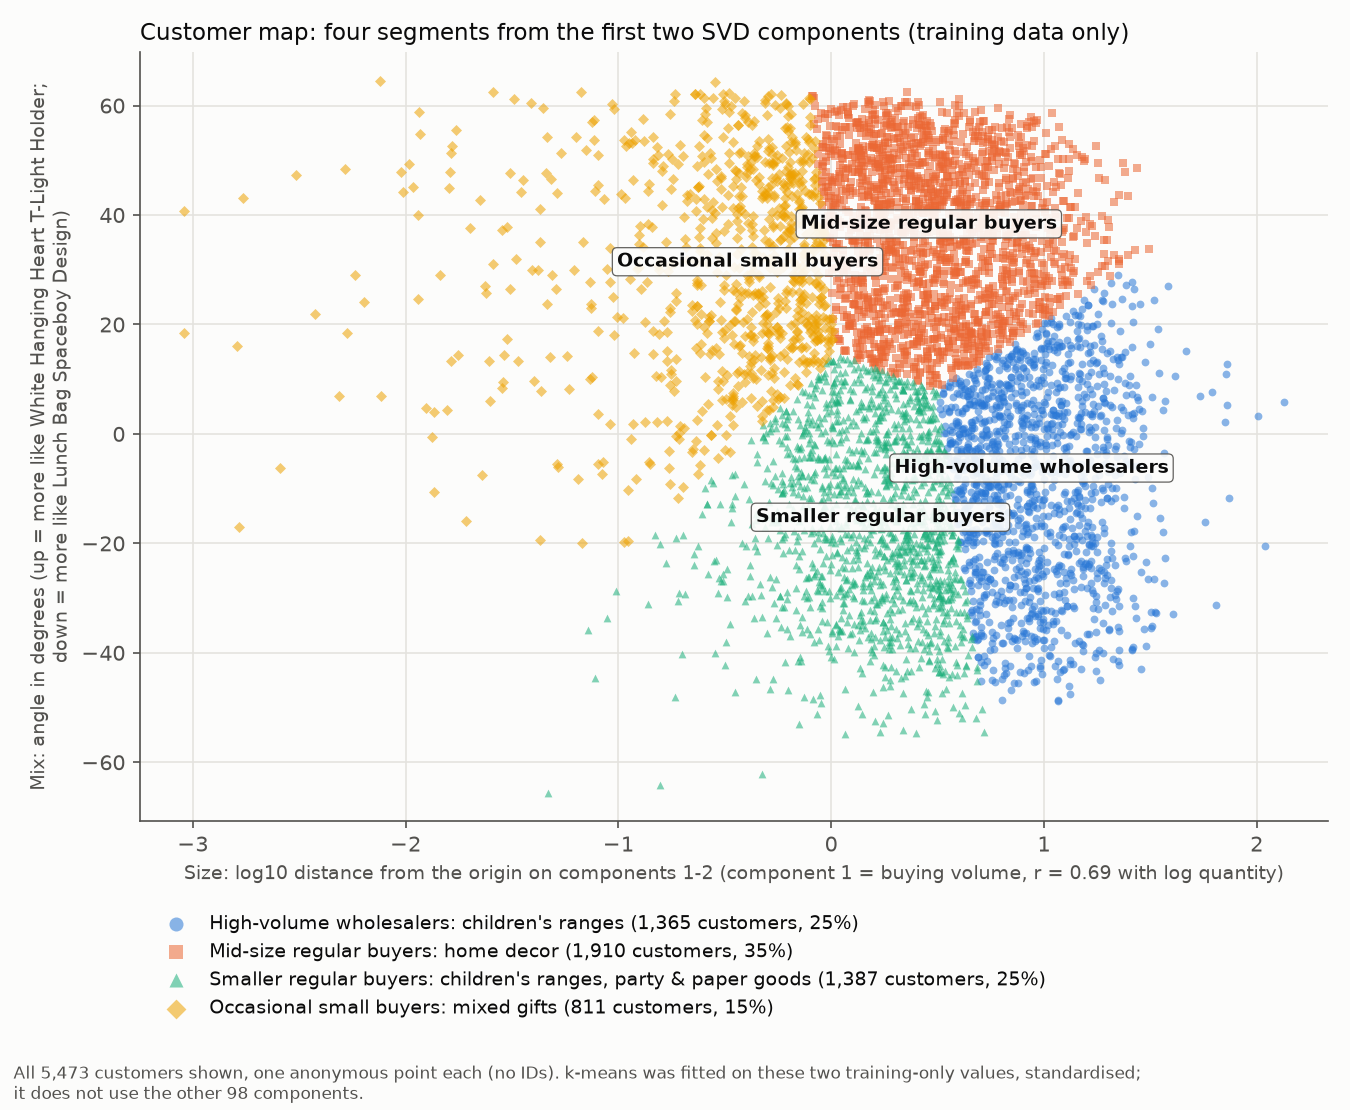

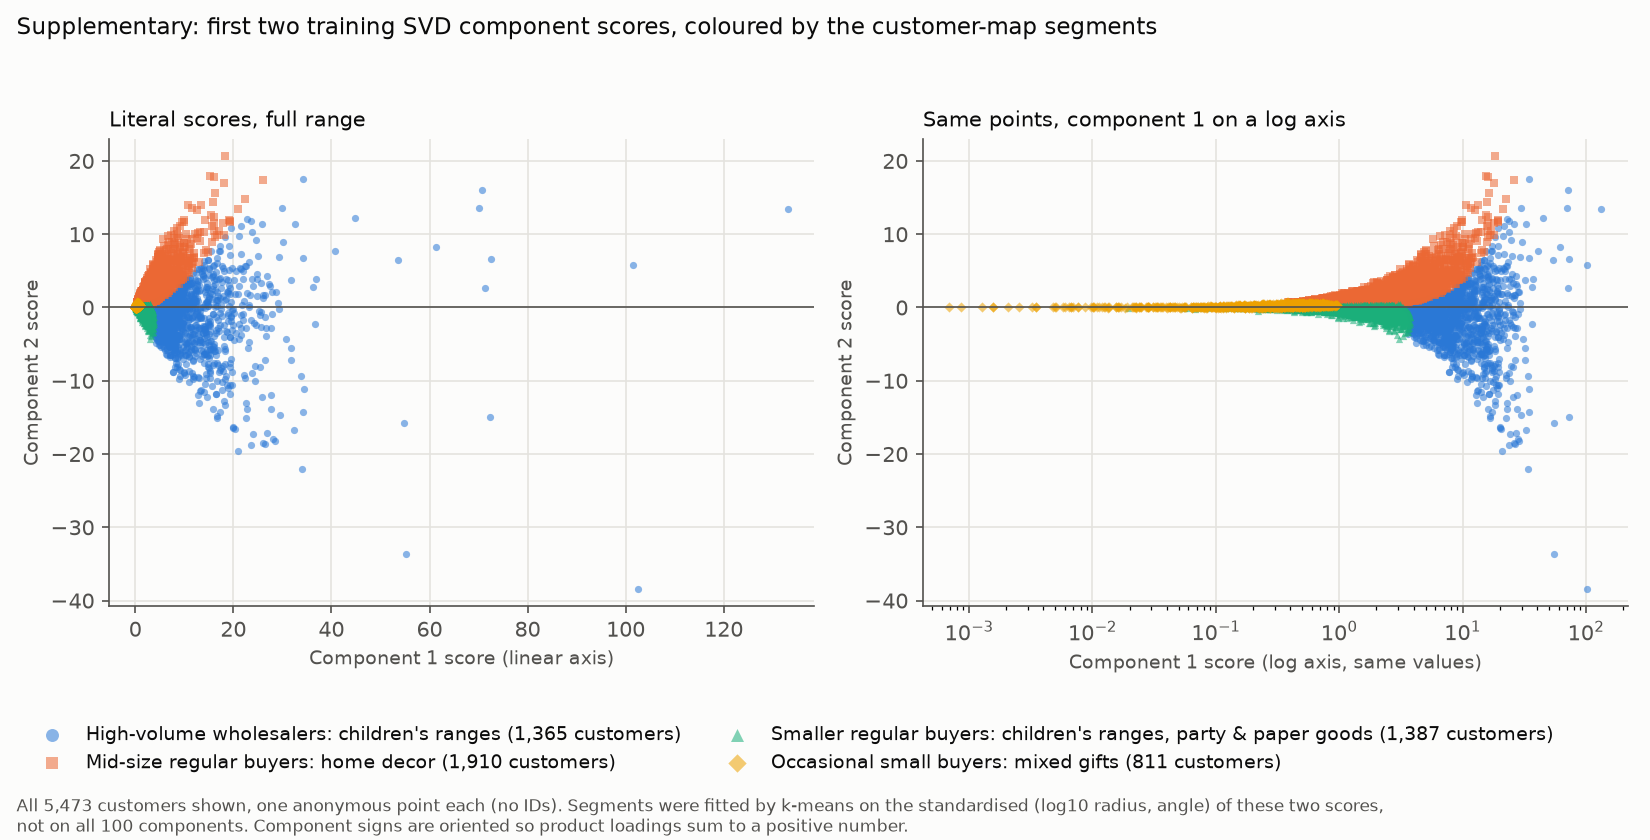

In [16]:
seg = pd.read_csv(REPORTS / "segments.csv")
assert seg["customers"].sum() == R["matrix"]["customers"]
display(seg)
display(Image(FIGURES / "customer_map.png"))
display(Image(FIGURES / "customer_map_components.png"))

In [17]:
profiles = json.loads((REPORTS / "segment_profiles.json").read_text())
comp2 = profiles["component_2"]
from string import capwords
lines = []
for p_ in profiles["segments"]:
    distinct = ", ".join(capwords(d["description"]) for d in p_["distinctive_products"][:4])
    top = ", ".join(capwords(d["description"]) for d in p_["top_products"][:3])
    lines.append(f'* **{p_["name"]}**: {p_["customers"]:,} customers ({p_["customer_share_pct"]:.0f}%), median '
                 f'{p_["median_quantity_per_customer"]:,.0f} units over the training period, '
                 f'{p_["avg_distinct_products"]:.0f} distinct products and {p_["avg_invoices"]:.1f} invoices on average, '
                 f'{p_["uk_share_pct"]:.0f}% UK. Most bought: {top}. Distinctive: {distinct}.')
display(Markdown("\n".join(lines)))
s = R["svd"]
segs = profiles["segments"]
intl = min(segs, key=lambda q: q["uk_share_pct"])
abroad = " and ".join(c["country"] for c in intl["countries"] if c["country"] != "United Kingdom")
lifts = [d["mix_lift"] for q in segs for d in q["distinctive_products"][:5]]
display(Markdown(f'''
**Reading the map, and its limits**

* Left to right is size. Component 1 correlates r = {s["component_1_volume_correlation"]:.2f} with log total quantity
  (Spearman {s["component_1_volume_spearman"]:.2f}) and r = {s["component_1_breadth_correlation"]:.2f} with the number of
  distinct products, so the first axis mostly says "how big a customer is", not "what kind".
* Up and down is product mix. Component 2 is barely related to volume (r = {comp2["volume_correlation"]:.2f}). It
  contrasts {", ".join(capwords(t) for t in comp2["top_products"][:3])} (up) with
  {", ".join(capwords(t) for t in comp2["negative_products"][:3])} (down).
* The points form one continuous cloud, not separate islands. The four groups are a useful partition for planning
  campaigns, not natural clusters, and customers near a boundary could go either way. Two components describe only
  a small part of each customer's buying, so segment-specific campaigns should be validated with a test.
* Country does not separate the groups: {segs[0]["overall_uk_share_pct"]:.0f}% of customers are UK based, so the
  names use products and volume, not geography. The most international segment is "{intl["name"]}", which is
  {100 - intl["uk_share_pct"]:.0f}% non-UK (mostly {abroad}).
* Distinctive products lean only modestly towards each segment (mix lift {min(lifts):.1f} to {max(lifts):.1f} for the
  five most distinctive products per segment). They mark tendencies, not exclusive tastes.
'''))

* **High-volume wholesalers: children's ranges**: 1,365 customers (25%), median 1,851 units over the training period, 170 distinct products and 12.4 invoices on average, 85% UK. Most bought: Pack Of 72 Retrospot Cake Cases, Lunch Bag Red Retrospot, Jumbo Bag Red Retrospot. Distinctive: Wrap Bird Garden, Dolly Girl Beaker, Woodland Mini Backpack, Spaceboy Beaker.
* **Mid-size regular buyers: home decor**: 1,910 customers (35%), median 462 units over the training period, 68 distinct products and 5.4 invoices on average, 97% UK. Most bought: White Hanging Heart T-light Holder, Assorted Colour Bird Ornament, Regency Cakestand 3 Tier. Distinctive: White Pearl Beaded Heart, Small, Heart Decoration With Pearls, Easter Decoration Hanging Bunny, Wood S/3 Cabinet Ant White Finish.
* **Smaller regular buyers: children's ranges, party & paper goods**: 1,387 customers (25%), median 273 units over the training period, 32 distinct products and 2.3 invoices on average, 86% UK. Most bought: Baking Set 9 Piece Retrospot, Pack Of 72 Retrospot Cake Cases, Retrospot Tea Set Ceramic 11 Pc. Distinctive: Nurse's Bag Soft Toy, Set Of 6 3d Kit Cards For Kids, S/6 Wooden Skittles In Cotton Bag, Baking Set Spaceboy Design.
* **Occasional small buyers: mixed gifts**: 811 customers (15%), median 77 units over the training period, 10 distinct products and 1.6 invoices on average, 98% UK. Most bought: Regency Cakestand 3 Tier, Rex Cash+carry Jumbo Shopper, Edwardian Parasol Natural. Distinctive: Edwardian Parasol Natural, Antique Silver Tea Glass Engraved, Edwardian Parasol Black, Edwardian Parasol Red.


**Reading the map, and its limits**

* Left to right is size. Component 1 correlates r = 0.69 with log total quantity
  (Spearman 0.88) and r = 0.89 with the number of
  distinct products, so the first axis mostly says "how big a customer is", not "what kind".
* Up and down is product mix. Component 2 is barely related to volume (r = -0.02). It
  contrasts White Hanging Heart T-light Holder, Heart Of Wicker Small, Assorted Colour Bird Ornament (up) with
  Lunch Bag Spaceboy Design, Round Snack Boxes Set Of4 Woodland, Plasters In Tin Spaceboy (down).
* The points form one continuous cloud, not separate islands. The four groups are a useful partition for planning
  campaigns, not natural clusters, and customers near a boundary could go either way. Two components describe only
  a small part of each customer's buying, so segment-specific campaigns should be validated with a test.
* Country does not separate the groups: 91% of customers are UK based, so the
  names use products and volume, not geography. The most international segment is "High-volume wholesalers: children's ranges", which is
  15% non-UK (mostly Germany and France).
* Distinctive products lean only modestly towards each segment (mix lift 1.6 to 5.2 for the
  five most distinctive products per segment). They mark tendencies, not exclusive tastes.


## ML7: sensitivity to the purchase value (count, 1/0, log)

The same k = 100, seed, ARPACK solver, cosine scoring and primary cohort are used each time. Only the stored
purchase value changes, and it also weights each past product in the customer profile. Each variant is fitted in
its own fresh process. This is a **sensitivity check, not a re-selection**: the log value was fixed by the Data
Engineer in DE4 before any test result, and it stays the main model.

In [18]:
sens = pd.read_csv(REPORTS / "sensitivity.csv")
display(sens.round(4))
hits = {w: ma.evaluate(ma.load_fit(f"svd_{w}_k100")[1]["customer_top_idx"], targets, coverage)["per_customer_hit"]
        for w in ma.WEIGHTINGS}
bin_vs_log = ma.paired_comparison(hits["binary"], hits["log"])
cnt_vs_log = ma.paired_comparison(hits["count"], hits["log"])
display(pd.DataFrame({"binary vs log": bin_vs_log, "count vs log": cnt_vs_log}).T.round(4))

,weighting,k,main_model,hit_rate_at_10,hits,evaluated_customers,recall_at_10,relative_error,fit_seconds,vs_baseline_difference,vs_baseline_ci95_low,vs_baseline_ci95_high
0,count,100,False,0.1291,247,1913,0.0093,0.1245,0.1345,-0.0450,-0.0669,-0.0225
1,binary,100,False,0.2493,477,1913,0.0282,0.7800,0.2337,0.0753,0.0507,0.0988
2,log,100,True,0.2321,444,1913,0.0284,0.7268,0.1860,0.0580,0.0340,0.0826


,difference,ci95_low,ci95_high,only_first_hit,only_second_hit,mcnemar_exact_p
binary vs log,0.0173,-0.0005,0.0355,181.0,148.0,0.0775
count vs log,-0.1030,-0.1239,-0.0826,114.0,311.0,0.0000


In [19]:
row = sens.set_index("weighting")
display(Markdown(f'''
* **Raw count is clearly worse**: {pct(row.loc["count", "hit_rate_at_10"])}, which is even below best sellers
  ({pct(R["baseline"]["hit_rate_at_10"])}). A few wholesale lines of thousands of units dominate the factors and the
  customer profiles. Its low reconstruction error ({row.loc["count", "relative_error"]:.3f}) is misleading: it mostly
  reflects rebuilding those few huge cells.
* **1/0 "ever bought" and log are close**: binary {pct(row.loc["binary", "hit_rate_at_10"])} against log
  {pct(row.loc["log", "hit_rate_at_10"])}, a difference of {100 * bin_vs_log["difference"]:.1f} points (95% interval
  {100 * bin_vs_log["ci95_low"]:.1f} to {100 * bin_vs_log["ci95_high"]:.1f}, McNemar p = {bin_vs_log["mcnemar_exact_p"]:.2f}).
  On this held-out window, ignoring how much was bought works at least as well as the log value.
* **Decision**: the main model stays log, as declared. Switching to binary because it scored better on the final
  test would choose the model on the test set, which R2 forbids. The finding is recorded as a next step: compare
  binary and log on a separate validation window carved from the training period before changing production.
'''))


* **Raw count is clearly worse**: 12.9%, which is even below best sellers
  (17.4%). A few wholesale lines of thousands of units dominate the factors and the
  customer profiles. Its low reconstruction error (0.124) is misleading: it mostly
  reflects rebuilding those few huge cells.
* **1/0 "ever bought" and log are close**: binary 24.9% against log
  23.2%, a difference of 1.7 points (95% interval
  -0.1 to 3.6, McNemar p = 0.08).
  On this held-out window, ignoring how much was bought works at least as well as the log value.
* **Decision**: the main model stays log, as declared. Switching to binary because it scored better on the final
  test would choose the model on the test set, which R2 forbids. The finding is recorded as a next step: compare
  binary and log on a separate validation window carved from the training period before changing production.


## Success targets: final check

These targets were written at the top of the README at the completion stage (see the README note), and are checked
here against the measured values.

In [20]:
T, s, b, N = R["targets"], R["svd"], R["baseline"], R["nightly"]
display(pd.DataFrame([
    ("Stored factors much smaller than the dense matrix (<= 10 MB)", f'{s["factor_mb"]:.3f} MB vs {R["matrix"]["dense_mb"]:.1f} MB dense', T["factor_target_met"]),
    ("Nightly fit + top-10 for every product <= 60 s (this machine)", f'{N["total_seconds"]:.2f} s', T["nightly_target_met"]),
    ("Model hit rate at 10 > best-seller baseline", f'{pct(s["hit_rate_at_10"])} vs {pct(b["hit_rate_at_10"])}', T["beats_baseline"]),
    ("Four customer groups marketing can name", f'{T["segments"]} named segments', T["segments_target_met"]),
], columns=["target", "measured", "met"]))

,target,measured,met
0,Stored factors much smaller than the dense matrix (<= 10 MB),7.328 MB vs 161.4 MB dense,True
1,Nightly fit + top-10 for every product <= 60 s (this machine),0.71 s,True
2,Model hit rate at 10 > best-seller baseline,23.2% vs 17.4%,True
3,Four customer groups marketing can name,4 named segments,True


## Decisions and risks (summary)

The full decision log, with reasons, is in `docs/decision_log.md`. The main risks for Sarah:

* **Cold start**: new customers and new products have no factors. Show them best sellers until they have history.
* **Seasonality**: the evaluation window is the pre-Christmas peak. Re-check hit rates on other months.
* **Drift**: refit nightly or weekly (it takes well under a second) and monitor the hit rate on the following weeks'
  purchases.
* **Privacy**: the factor files and top-10 tables live under the git-ignored `data/processed/`. Customer factors
  are per-customer data and must be treated like the IDs. Everything in `reports/` and `figures/` is aggregate.